In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only ".
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory



# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

## EDA

In [2]:
# imports
import librosa
import torch
from torch.utils.data import Dataset,DataLoader
import os

In [3]:
# load a audio file (blues 1st song, bass wav)

audio ,sr = librosa.load("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/blues/blues.00000/bass.wav")

In [4]:
# mel spectrogram
mel = librosa.feature.melspectrogram(y=audio, sr=sr)

In [5]:
mel

array([[2.5745332e-01, 4.2675146e-01, 3.2385409e-01, ..., 5.5470359e-01,
        1.5174493e-01, 4.1603036e-03],
       [5.8392060e-01, 1.2215375e+00, 3.6529534e+00, ..., 1.5887866e+00,
        5.3091729e-01, 1.8637583e-02],
       [1.2238587e-01, 2.7050793e-01, 2.8159003e+00, ..., 1.2438349e+00,
        1.3502882e-01, 1.0573348e-02],
       ...,
       [1.2283579e-07, 3.2386751e-08, 1.5159799e-09, ..., 1.9238520e-09,
        7.8867082e-09, 3.1313675e-07],
       [8.4263490e-08, 2.2608516e-08, 8.8741103e-10, ..., 6.3908812e-10,
        6.9405508e-09, 3.1582761e-07],
       [2.2079082e-08, 5.8383747e-09, 9.2087366e-11, ..., 8.4879451e-11,
        4.6800928e-09, 2.4455849e-07]], dtype=float32)

In [6]:
sr

22050

In [7]:
# first rock song bass file
rock ,rsr = librosa.load("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/rock/rock.00000/bass.wav")

In [8]:
rsr

22050

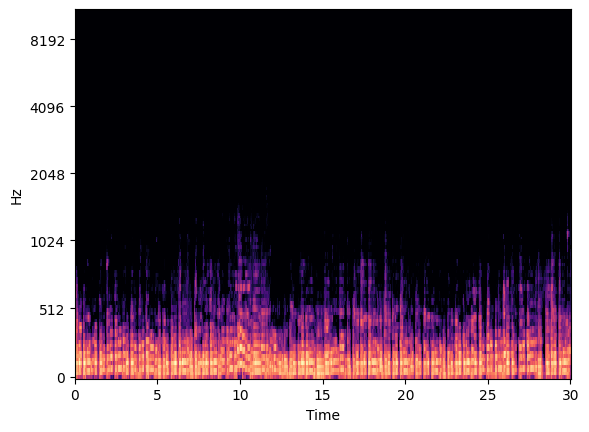

In [9]:
# Mel Spectrogram display - decibel values bcz raw values are large
# (blues bass)
librosa.display.specshow(
    librosa.power_to_db(mel,ref=np.max),
    sr=sr,
    x_axis='time',
    y_axis='mel'   
)


In [10]:
# rock melspectrogram
mel_rock = librosa.feature.melspectrogram(y=rock,sr=rsr)

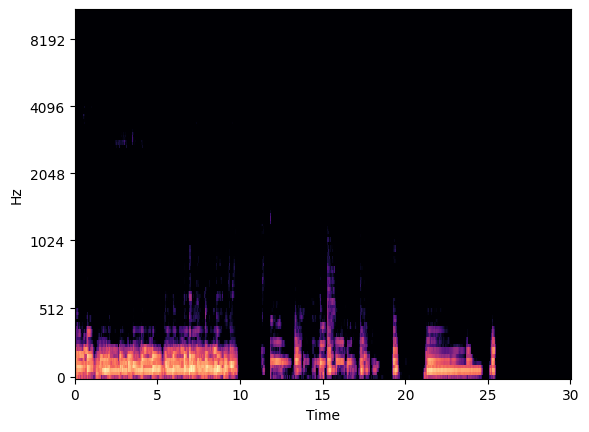

In [11]:
# rock bass melspectrogram display 
librosa.display.specshow(
    librosa.power_to_db(mel_rock,ref=np.max),
    sr=rsr,
    x_axis='time',
    y_axis ='mel'
)


### Dataset

In [12]:
# Goal: load whole dataset together instead of loading one audio file 

## make a dataset and dataloader

### train the model 

In [13]:
# custom dataset
class MyDataset(Dataset):
    def __init__(self,root_dir,sr): #sampling rate(fixed)
        self.files =[] # files that we'll save
        self.sr = sr
        self.labels = [] #labels for root dir
        
        for label , genre_dir in enumerate(os.listdir(root_dir)):
            song_dir = os.path.join(root_dir,genre_dir)
            for file in (os.listdir(song_dir)):
                file_path=os.path.join(song_dir,file)
                for song in (os.listdir(file_path)):
                    wav_files = os.path.join(file_path,song)
                    self.files.append(wav_files) # final wav files
                    self.labels.append(label)
            
        
    def __len__(self):
        return len(self.files)
        
    def __getitem__(self,idx):
        audio , sr = librosa.load(self.files[idx],sr =self.sr)
        return torch.tensor(audio),self.labels[idx]
        

In [14]:
# dataset instance
dataset = MyDataset("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems",22050)

In [15]:
dataset[1250]

(tensor([-0.0051, -0.0072, -0.0064,  ...,  0.0021,  0.0020,  0.0020]), 3)

In [16]:
len(dataset)

4000

In [17]:
len(dataset.labels)

4000

### DataLoader

In [18]:
# dataloader instance
loader = DataLoader(dataset,batch_size=32,shuffle=True)

In [19]:
device = "cuda" if torch.cuda.is_available() else "gpu"